In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [3]:
df = pd.read_csv("../data/Churn_Modelling.csv")
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

categorical_features = ["Geography", "Gender"]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

crossValidation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [4]:
depths = [1, 2, 3, 5, 10, 20]
train_accuracies = []
validation_accuracies = []

for depth in depths:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                criterion="entropy",
                random_state=42
            ))
        ]
    )

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=crossValidation,
        scoring="accuracy",
        return_train_score=True
    )

    train_accuracies.append(results["train_score"].mean())
    validation_accuracies.append(results["test_score"].mean())

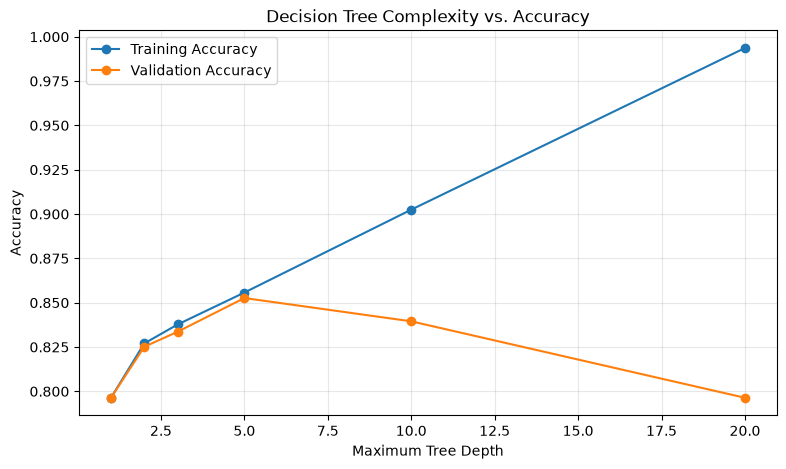

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    validation_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Complexity vs. Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
depths = [1, 2, 3, 5, 10, 20]
validation_f1 = []
validation_recall = []

for depth in depths:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                criterion="entropy",
                random_state=42
            ))
        ]
    )

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=crossValidation,
        scoring=["f1", "recall"]
    )

    validation_f1.append(results["test_f1"].mean())
    validation_recall.append(results["test_recall"].mean())

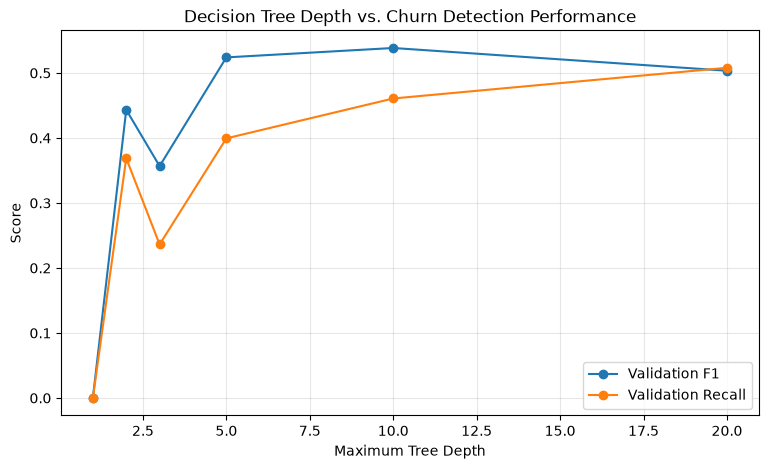

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    validation_f1,
    marker="o",
    label="Validation F1"
)

plt.plot(
    depths,
    validation_recall,
    marker="o",
    label="Validation Recall"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Score")
plt.title("Decision Tree Depth vs. Churn Detection Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()